In [2]:
import pandas as pd
import numpy as np
import cv2
import os
import re
from tqdm import tqdm

import glob
from glob import glob as glob

import matplotlib.pyplot as plt

In [3]:
"""
Item 1: time stamps.
Item 2: frame number of the current frame (video length 150 s, 30 fps, frame number: 1-4500).
Item 3-4: head orientation in the longitude ([-180 degree, +180 degree]) and latitude ([-90 degree, +90 degree]) of the 360-degree world.
Item 5-6: eye-in-head data, i.e. on-screen gaze positions. (0, 0) at bottom-left of the screen, (1, 1) at top-right.
Item 7-8: gaze-in-world data, i.e. gaze positions in the longitude ([-180 degree, +180 degree]) and latitude ([-90 degree, +90 degree]).
"""

datadir_path = "/home/cp/Documents/Libra/access/data/ET_dataset"

raw_datadir = "RawData"
file_list = "filelist.txt"

# HTC Vive FOV
hor_fov = 108.77
ver_fov = 111.53

with open(os.path.join(datadir_path, raw_datadir, file_list)) as f:
    file_list = [line.strip() for line in f.readlines()]

print("Number of recordings:", len(file_list))
print("Example file:", file_list[0])

Number of recordings: 360
Example file: User_01_Video_01_Task_1.txt


In [8]:
def convert_hor_degre(degrees):
    return (degrees + 180 + 360) % 360


def convert_ver_degree(degrees):
    # -1 because the y-axis is inverted for opencv
    return ((-1) * degrees + 90 + 360) % 360


video_paths = glob(os.path.join(datadir_path, "Videos", "*.mp4"))

# Define specific tasks to extract frames, if None extracts from all
# Tasks 1-4：Free viewing, Visual search, Saliency, and Track
tasks = None

# FOV in horizontal and vertical axes (replace with the HMD values)
fov_horizontal, fov_vertical = 108.77, 111.53

# Define a regular expression pattern to match the video number
pattern_vn = r"Video_(\d+)"
pattern_fn = r"User_(\d+)_Video_(\d+)_Task_(\d+)\.txt"
for vp in video_paths[5:]:
    vp_number = int(os.path.basename(vp).split("-")[0].split("Video ")[1])
    valid_files = []
    for file_name in file_list:
        # Use re.search to find the match in the file name
        match = re.search(pattern_vn, file_name)
        # Check if a match is found
        if match:
            # Extract the video number from the match
            video_number = int(match.group(1))
            # Check if the video number matches
            if vp_number == video_number:
                valid_files.append(file_name)
        else:
            print("A video does not follow the format")
            pass
    # Extract frames according to task_id
    for filename in valid_files[0:1]:
        match = re.match(pattern_fn, filename)
        if match:
            if tasks == None:
                tasks = [1, 2, 3, 4]
            for task_id in tasks:
                if task_id == int(match.group(3)):
                    savename = filename.split(".")[0]
                    # Output video file path
                    output_video_path = f"explore_video_results/{savename}.mp4"
                    # Create a VideoWriter object
                    fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec
                    output_video = cv2.VideoWriter(
                        output_video_path, fourcc, 30.0, (1920, 1080)
                    )

                    # Read the gaze data from the text file
                    gaze_data = pd.read_csv(
                        os.path.join(datadir_path, raw_datadir, filename),
                        sep="\t",
                        names=[
                            "timestamp",
                            "frame",
                            "hmd_long",
                            "hmd_lat",
                            "eih_x",
                            "eih_y",
                            "giw_long",
                            "giw_lat",
                        ],
                    )
                    # Drop duplicate rows based on the 'frame' column
                    df_unique_frames = gaze_data.drop_duplicates(
                        subset="frame"
                    ).sort_values(by="frame")

                    # Open the video file
                    cap = cv2.VideoCapture(vp)
                    # Get the total number of frames in the video
                    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

                    # FOR LOOP FOR MULTI give dataset of frames with the same cap
                    # Iterate over the DataFrame and access the 'frame' column
                    for index, row in tqdm(
                        df_unique_frames.head(1000).iterrows(),
                        total=df_unique_frames.head(1000).shape[0],
                    ):

                        fnumber = int(row["frame"])
                        horz_hmd_deg = row["hmd_long"]
                        vert_hmd_deg = row["hmd_lat"]
                        giw_long = row["giw_long"]
                        giw_lat = row["giw_lat"]
                        eih_x = row["eih_x"]
                        eih_y = row["eih_y"]

                        # Set the frame number and get frame
                        cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber - 1)
                        res, frame = cap.read()

                        if res:
                            frame = cv2.resize(frame, (1920, 1080))
                            # Video dimensions
                            width, height = frame.shape[1], frame.shape[0]
                            # Conersion of deegre ranges (-180,180) to (0, 360) and (-90, 90) to (0, 180)
                            # hmd
                            yaw_hmd = convert_hor_degre(horz_hmd_deg)
                            pitch_hmd = convert_ver_degree(vert_hmd_deg)
                            # Gaze
                            giw_long = convert_hor_degre(giw_long)
                            giw_lat = convert_ver_degree(giw_lat)

                            # Calculate FOV boundaries in equirectangular coordinates
                            # Hmd FOV
                            fov_left = int((yaw_hmd - fov_horizontal / 2) * width / 360)
                            fov_right = int(
                                (yaw_hmd + fov_horizontal / 2) * width / 360
                            )
                            fov_top = int((pitch_hmd - fov_vertical / 2) * height / 180)
                            fov_bottom = int(
                                (pitch_hmd + fov_vertical / 2) * height / 180
                            )

                            # Create a copy of the frame to draw the rectangle on
                            visualization_frame = frame.copy()

                            # Handle wrapping for FOV rectangle
                            if fov_right > width:
                                cv2.rectangle(
                                    visualization_frame,
                                    (fov_left, fov_top),
                                    (width, fov_bottom),
                                    (255, 255, 0),
                                    4,
                                )
                                cv2.rectangle(
                                    visualization_frame,
                                    (0, fov_top),
                                    (fov_right - width, fov_bottom),
                                    (255, 255, 0),
                                    4,
                                )
                            else:
                                cv2.rectangle(
                                    visualization_frame,
                                    (fov_left, fov_top),
                                    (fov_right, fov_bottom),
                                    (255, 255, 0),
                                    4,
                                )

                            # Handle wrapping for circle (giw_long, giw_lat)
                            center = (
                                int(giw_long * width / 360),
                                int(giw_lat * height / 180),
                            )
                            if center[0] < 0:
                                cv2.circle(
                                    visualization_frame,
                                    (width + center[0], center[1]),
                                    50,
                                    (0, 255, 0),
                                    4,
                                )
                            else:
                                cv2.circle(
                                    visualization_frame, center, 50, (0, 255, 0), 4
                                )

                            # Handle wrapping for circle (eih_x, eih_y) in the FOV rectangle
                            center = (
                                int(fov_left + eih_x * (fov_right - fov_left)),
                                int(fov_top + (1 - eih_y) * (fov_bottom - fov_top)),
                            )
                            if center[0] < 0:
                                cv2.circle(
                                    visualization_frame,
                                    (width + center[0], center[1]),
                                    10,
                                    (0, 0, 255),
                                    -1,
                                )
                            else:
                                cv2.circle(
                                    visualization_frame, center, 10, (0, 0, 255), -1
                                )

                            # Crop the area of interest from the original frame, considering wrapping
                            if fov_right > width:
                                cropped_frame_left = frame[
                                    fov_top:fov_bottom, fov_left:
                                ].copy()
                                cropped_frame_right = frame[
                                    fov_top:fov_bottom, : fov_right - width
                                ].copy()
                                cropped_frame = np.hstack(
                                    (cropped_frame_left, cropped_frame_right)
                                )
                            else:
                                cropped_frame = frame[
                                    fov_top:fov_bottom, fov_left:fov_right
                                ].copy()

                            # Save the current frame to the video file
                            output_video.write(visualization_frame)

                            # # Display the visualization frame
                            # plt.figure(figsize=(15, 9))
                            # plt.imshow(cv2.cvtColor(visualization_frame, cv2.COLOR_BGR2RGB))
                            # plt.axis('off')  # Turn off axis labels
                            # plt.tight_layout()
                            # Release video capture object
                            # Release the video writer
                    output_video.release()
                    cap.release()

 22%|██▏       | 222/1000 [00:33<01:58,  6.56it/s]


KeyboardInterrupt: 

In [34]:
def convert_hor_degre(degrees):
    return (degrees + 180 + 360) % 360


def convert_ver_degree(degrees):
    # -1 because the y-axis is inverted for opencv
    return ((-1) * degrees + 90 + 360) % 360


# FOV in horizontal and vertical axes (replace with the HMD values)
fov_horizontal, fov_vertical = 108.77, 111.53

savename = filename.split(".")[0]
# Output video file path
output_video_path = f"explore_video_results/{savename}.mp4"
# Create a VideoWriter object
fourcc = cv2.VideoWriter_fourcc(*"mp4v")  # Specify the codec
output_video = cv2.VideoWriter(output_video_path, fourcc, 30.0, (1920, 1080))

# Open the video file
cap = cv2.VideoCapture(vp)
# Get the total number of frames in the video
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))


# FOR LOOP FOR MULTI give dataset of frames with the same cap
# Iterate over the DataFrame and access the 'frame' column
for index, row in tqdm(
    df_unique_frames.head(1000).iterrows(), total=df_unique_frames.head(1000).shape[0]
):

    fnumber = int(row["frame"])
    horz_hmd_deg = row["hmd_long"]
    vert_hmd_deg = row["hmd_lat"]
    giw_long = row["giw_long"]
    giw_lat = row["giw_lat"]
    eih_x = row["eih_x"]
    eih_y = row["eih_y"]

    # Set the frame number and get frame
    cap.set(cv2.CAP_PROP_POS_FRAMES, fnumber - 1)
    res, frame = cap.read()

    if res:
        frame = cv2.resize(frame, (1920, 1080))
        # Video dimensions
        width, height = frame.shape[1], frame.shape[0]
        # Conersion of deegre ranges (-180,180) to (0, 360) and (-90, 90) to (0, 180)
        # hmd
        yaw_hmd = convert_hor_degre(horz_hmd_deg)
        pitch_hmd = convert_ver_degree(vert_hmd_deg)
        # Gaze
        giw_long = convert_hor_degre(giw_long)
        giw_lat = convert_ver_degree(giw_lat)

        # Calculate FOV boundaries in equirectangular coordinates
        # Hmd FOV
        fov_left = int((yaw_hmd - fov_horizontal / 2) * width / 360)
        fov_right = int((yaw_hmd + fov_horizontal / 2) * width / 360)
        fov_top = int((pitch_hmd - fov_vertical / 2) * height / 180)
        fov_bottom = int((pitch_hmd + fov_vertical / 2) * height / 180)

        # Create a copy of the frame to draw the rectangle on
        visualization_frame = frame.copy()

        # Draw a circle at the specified coordinates (giw_long, giw_lat)
        center = (int(giw_long * width / 360), int(giw_lat * height / 180))
        radius = 50  # You can adjust the radius as needed
        cv2.circle(
            visualization_frame, center, radius, (0, 255, 0), 4
        )  # -1 fills the circle
        # Draw a rectangle around the cropped FOV area in the visualization frame
        cv2.rectangle(
            visualization_frame,
            (fov_left, fov_top),
            (fov_right, fov_bottom),
            (255, 255, 0),
            4,
        )
        # Draw a circle at the specified coordinates (eih_x, eih_y) in teh FOV rectavgle
        radius = 10  # You can adjust the radius as needed
        cv2.circle(
            visualization_frame, center, 10, (0, 0, 255), -1
        )  # -1 fills the circle

        # Add frame counter text
        text_frame_counter = f"Frame: {fnumber}/{total_frames}"
        cv2.putText(
            visualization_frame,
            text_frame_counter,
            (100, 100),
            cv2.FONT_HERSHEY_SIMPLEX,
            2,
            (0, 0, 0),
            4,
        )
        # Add text to display yaw and pitch degrees on the visualization frame
        text = f"Yaw: {horz_hmd_deg} degrees Pitch: {vert_hmd_deg} degrees"
        cv2.putText(
            visualization_frame,
            f"Yaw: {horz_hmd_deg}",
            (100, 200),
            cv2.FONT_HERSHEY_SIMPLEX,
            2,
            (0, 0, 0),
            4,
        )
        cv2.putText(
            visualization_frame,
            f"Pitch: {vert_hmd_deg} degrees",
            (100, 300),
            cv2.FONT_HERSHEY_SIMPLEX,
            2,
            (0, 0, 0),
            4,
        )
        # Save the current frame to the video file
        output_video.write(visualization_frame)

        # # Display the visualization frame
        # plt.figure(figsize=(15, 9))
        # plt.imshow(cv2.cvtColor(visualization_frame, cv2.COLOR_BGR2RGB))
        # plt.axis('off')  # Turn off axis labels
        # plt.tight_layout()
        # Release video capture object
        # Release the video writer
output_video.release()
cap.release()

100%|██████████| 1000/1000 [02:25<00:00,  6.87it/s]


In [90]:
print(fov_left)

3222


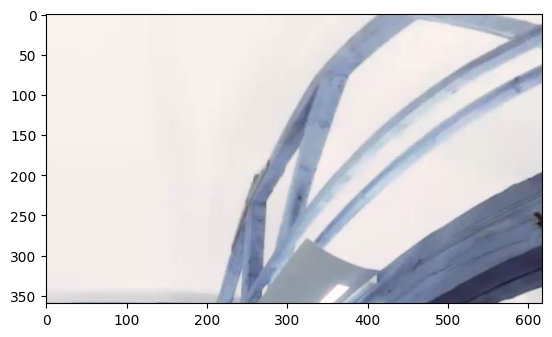

In [91]:
plt.imshow(cropped_frame)